# AI-Powered Intelligent Trade Settlement Failure Prediction and Explainable Risk Management System

### UC Berkeley Professional Certificate in Machine Learning & Artificial Intelligence — Capstone Project

**Self-contained executable edition**

This notebook is intentionally designed so that **each major analysis/model code cell can run independently**.  
Each scenario cell:

- imports the libraries it needs,
- finds and loads the synthetic trade dataset,
- recreates required engineered features,
- recreates the leakage-safe temporal split where applicable,
- trains/evaluates the relevant model,
- produces the required tables/plots,
- includes detailed comments explaining the business and ML reasoning.

This design reduces hidden notebook-state dependencies and makes debugging much easier.

> **Dataset requirement:** keep `trade_settlement_synthetic.csv` either in `./data/`, `../data/`, the same folder as the notebook, or update the candidate paths inside a scenario cell.

> **Important:** The trade-level dataset is synthetic and is intended for academic demonstration only.

# 0. Environment and Dependencies

Run this cell once when setting up a new Python environment.

It checks for the required packages and installs only missing ones.  
Core packages:

- numpy
- pandas
- matplotlib
- scipy
- scikit-learn

Advanced/optional packages:

- xgboost
- catboost
- shap

If your university environment blocks package installation, install the same packages from a terminal or use the supplied `requirements.txt`.

In [1]:
# ================================================================
# ENVIRONMENT / DEPENDENCY SETUP
# This cell can be run independently.
# ================================================================

import sys
import subprocess
import importlib.util

REQUIRED = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "xgboost": "xgboost",
    "catboost": "catboost",
    "shap": "shap",
}

missing = [
    pip_name
    for module_name, pip_name in REQUIRED.items()
    if importlib.util.find_spec(module_name) is None
]

if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet", *missing
    ])
else:
    print("All required packages are already installed.")

print("\nPython:", sys.version)

Installing missing packages: ['xgboost', 'catboost', 'shap']

Python: 3.11.15 | packaged by Anaconda, Inc. | (main, Mar 11 2026, 17:12:15) [MSC v.1942 64 bit (AMD64)]


# 1. Business Problem and Dataset Validation

### Problem statement

> Can machine learning identify securities trades at elevated risk of settlement failure early enough for operations teams to intervene before settlement?

Primary target:

- `settlement_failed = 0` → settled
- `settlement_failed = 1` → failed

The first executable scenario loads and validates the data independently.

In [2]:
# ================================================================
# SCENARIO 1 — DATA LOADING / VALIDATION
# Fully self-contained: imports + dataset discovery + validation.
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np

# Search common locations so the notebook is portable.
DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]

DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "trade_settlement_synthetic.csv was not found. "
        "Place it beside the notebook or inside a data/ folder."
    )

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["trade_date", "settlement_date"]
).sort_values("trade_date").reset_index(drop=True)

print("Dataset:", DATA_PATH)
print("Shape:", df.shape)
print("Date range:", df["trade_date"].min().date(), "to", df["trade_date"].max().date())
print("Duplicate Trade IDs:", df["trade_id"].duplicated().sum())
print("Settlement failure rate:", f'{df["settlement_failed"].mean():.2%}')

print("\nFirst five rows:")
display(df.head())

print("\nMissing-value counts:")
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("missing_count"))

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

Dataset: ..\data\trade_settlement_synthetic.csv
Shape: (25000, 37)
Date range: 2023-01-02 to 2025-11-28
Duplicate Trade IDs: 0
Settlement failure rate: 1.96%

First five rows:


,trade_id,trade_date,settlement_date,asset_class,buy_sell,currency,market,settlement_location,counterparty_id,custodian,...,security_liquidity_score,market_volatility_index,inventory_shortfall_indicator,counterparty_avg_trade_amount,trade_size_ratio,pre_settlement_note,settlement_failed,settlement_delay_hours,failure_reason,failure_reason_description
0,TRD0001488,2023-01-02,2023-01-04,ETF,BUY,CAD,EU,JASDEC,CP074,CUST04,...,0.4493,22.74,0,1997496.48,0.0895,late confirmation,0,0.04,SETTLED,Trade settled successfully with no final excep...
1,TRD0024982,2023-01-02,2023-01-03,Equity,BUY,USD,US,DTC,CP011,CUST03,...,0.6673,22.82,0,2246662.42,0.2588,normal pre-settlement processing,0,0.05,SETTLED,Trade settled successfully with no final excep...
2,TRD0023819,2023-01-02,2023-01-04,Corporate Bond,BUY,CAD,UK,CREST,CP010,CUST06,...,0.4417,21.44,0,59180.70,40.0000,counterparty recent fail rate elevated,0,0.56,SETTLED,Trade settled successfully with no final excep...
3,TRD0021997,2023-01-02,2023-01-03,Equity,SELL,EUR,CA,CDS,CP061,CUST01,...,0.5992,32.39,0,2479677.25,0.4910,counterparty recent fail rate elevated,0,0.00,SETTLED,Trade settled successfully with no final excep...
4,TRD0021840,2023-01-02,2023-01-04,Equity,BUY,USD,US,DTC,CP006,CUST07,...,0.8685,23.06,0,405203.08,35.9604,normal pre-settlement processing,0,0.69,SETTLED,Trade settled successfully with no final excep...



Missing-value counts:


,missing_count



Data types:


,dtype
trade_id,str
trade_date,datetime64[us]
settlement_date,datetime64[us]
asset_class,str
buy_sell,str
currency,str
market,str
settlement_location,str
counterparty_id,str
custodian,str


# 2. Data Leakage Control

A settlement-failure model must use only information available **before** the final outcome.

The following fields are post-outcome and must not enter the predictive model:

- `settlement_failed` — classification target
- `settlement_delay_hours` — realized outcome
- `failure_reason`
- `failure_reason_description`

The cell below independently checks the approved feature set against the leakage list.

In [3]:
# ================================================================
# SCENARIO 2 — LEAKAGE-SAFE FEATURE VALIDATION
# ================================================================

from pathlib import Path
import pandas as pd

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH)

TARGET = "settlement_failed"

PRE_PREDICTION_FEATURES = [
    "asset_class", "buy_sell", "currency", "market", "settlement_location",
    "counterparty_id", "custodian", "trade_amount", "quantity",
    "settlement_days", "cross_border", "month_end", "quarter_end",
    "market_holiday_mismatch", "ssi_status", "confirmation_delay_minutes",
    "allocation_delay_minutes", "affirmation_delay_minutes", "matching_attempts",
    "trade_amendments", "hours_until_cutoff", "prior_fail_rate_30d",
    "prior_fail_rate_90d", "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "counterparty_avg_trade_amount", "trade_size_ratio"
]

POST_OUTCOME_COLUMNS = [
    "settlement_failed",
    "settlement_delay_hours",
    "failure_reason",
    "failure_reason_description"
]

missing_features = sorted(set(PRE_PREDICTION_FEATURES) - set(df.columns))
leaked_features = sorted(set(PRE_PREDICTION_FEATURES).intersection(POST_OUTCOME_COLUMNS))

print("Approved predictive feature count:", len(PRE_PREDICTION_FEATURES))
print("Missing approved fields:", missing_features)
print("Leakage fields incorrectly included:", leaked_features)

assert not missing_features, f"Expected predictive fields are missing: {missing_features}"
assert not leaked_features, f"Leakage detected: {leaked_features}"

print("\nPASS — Approved feature set contains no defined post-outcome fields.")

Approved predictive feature count: 29
Missing approved fields: []
Leakage fields incorrectly included: []

PASS — Approved feature set contains no defined post-outcome fields.


# 3. Exploratory Data Analysis

This independently runnable cell addresses several core EDA questions:

- How rare are failures?
- Which SSI states show the highest failure rates?
- Do failed trades have longer confirmation delays?
- Is recent counterparty history associated with current outcomes?
- Does inventory shortfall correspond to elevated failures?

Because the event is rare, the notebook will later emphasize **precision, recall, F1, ROC-AUC, and PR-AUC** rather than accuracy.

Settlement outcomes


,count,rate
settlement_failed,,
Settled,24511,0.98044
Failed,489,0.01956


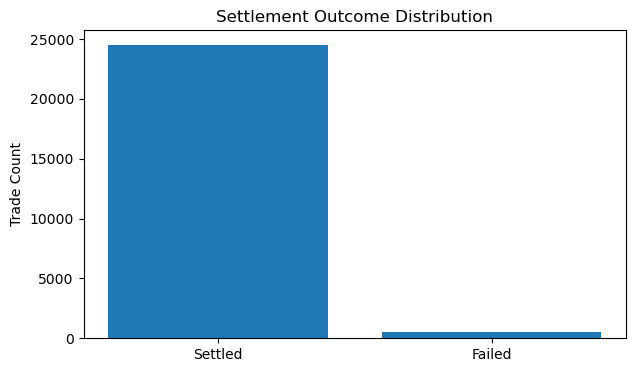


Failure rate by SSI status


,mean,count
ssi_status,,
MISSING,0.137540,618
CHANGED,0.044867,1315
VALID,0.014956,23067


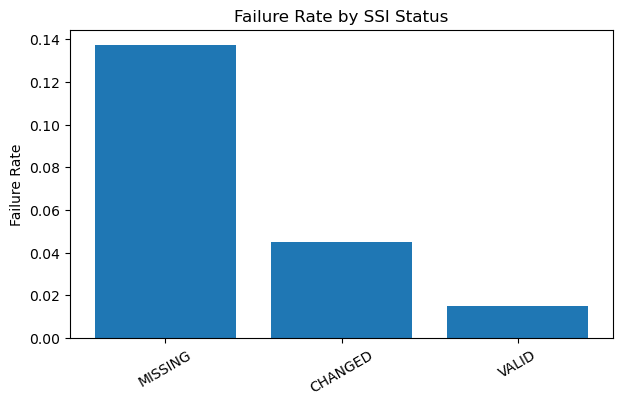


Confirmation delay by outcome


,median,mean,std,count
settlement_failed,,,,
Settled,26.73,31.883410,22.457056,24511
Failed,29.57,36.800491,28.890094,489



Prior 30-day counterparty fail rate by current outcome


,median,mean,std
settlement_failed,,,
Settled,0.0785,0.091993,0.066412
Failed,0.1187,0.127368,0.074440



Failure rate by inventory-shortfall indicator


,mean,count
inventory_shortfall_indicator,,
0,0.018084,24220
1,0.065385,780



Failure rate by asset class


,mean,count
asset_class,,
ETF,0.021063,2991
Equity,0.019683,10669
Government Bond,0.019064,4616
Corporate Bond,0.019036,6724


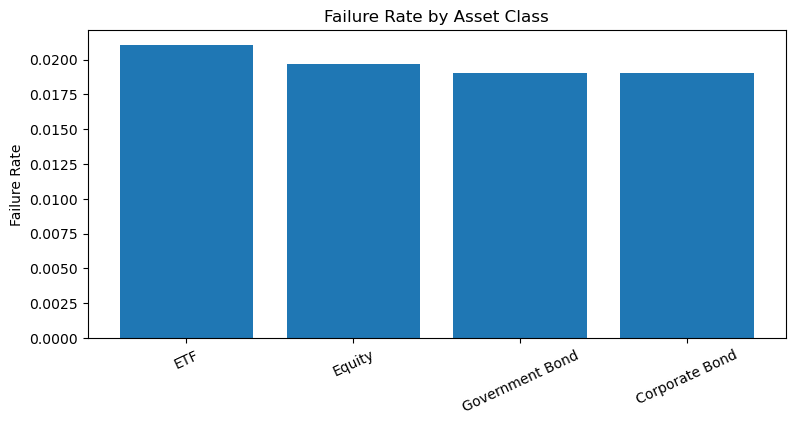

In [4]:
# ================================================================
# SCENARIO 3 — EXPLORATORY DATA ANALYSIS
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date", "settlement_date"])
TARGET = "settlement_failed"

# 1) Target distribution
outcome = df[TARGET].value_counts().sort_index()
rates = df[TARGET].value_counts(normalize=True).sort_index()

print("Settlement outcomes")
display(pd.DataFrame({"count": outcome, "rate": rates}).rename(index={0:"Settled", 1:"Failed"}))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(["Settled", "Failed"], [outcome.get(0, 0), outcome.get(1, 0)])
ax.set_title("Settlement Outcome Distribution")
ax.set_ylabel("Trade Count")
plt.show()

# 2) SSI failure rate
ssi = df.groupby("ssi_status")[TARGET].agg(["mean", "count"]).sort_values("mean", ascending=False)
print("\nFailure rate by SSI status")
display(ssi)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(ssi.index.astype(str), ssi["mean"])
ax.set_title("Failure Rate by SSI Status")
ax.set_ylabel("Failure Rate")
ax.tick_params(axis="x", rotation=30)
plt.show()

# 3) Confirmation delay distribution summary
print("\nConfirmation delay by outcome")
display(
    df.groupby(TARGET)["confirmation_delay_minutes"]
      .agg(["median", "mean", "std", "count"])
      .rename(index={0:"Settled", 1:"Failed"})
)

# 4) Historical counterparty failure rate
print("\nPrior 30-day counterparty fail rate by current outcome")
display(
    df.groupby(TARGET)["prior_fail_rate_30d"]
      .agg(["median", "mean", "std"])
      .rename(index={0:"Settled", 1:"Failed"})
)

# 5) Inventory shortfall
inventory = (
    df.groupby("inventory_shortfall_indicator")[TARGET]
      .agg(["mean", "count"])
      .sort_index()
)
print("\nFailure rate by inventory-shortfall indicator")
display(inventory)

# 6) Asset class
asset = df.groupby("asset_class")[TARGET].agg(["mean", "count"]).sort_values("mean", ascending=False)
print("\nFailure rate by asset class")
display(asset)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(asset.index.astype(str), asset["mean"])
ax.set_title("Failure Rate by Asset Class")
ax.set_ylabel("Failure Rate")
ax.tick_params(axis="x", rotation=25)
plt.show()

# 4. Statistical Investigation

Two tests are included:

1. **Chi-square test** — Is SSI status associated with settlement outcome?
2. **Mann-Whitney U test** — Do confirmation-delay distributions differ between failed and settled trades?

Statistical association does not prove causality.

In [5]:
# ================================================================
# SCENARIO 4 — STATISTICAL TESTS
# ================================================================

from pathlib import Path
import pandas as pd
from scipy.stats import chi2_contingency, mannwhitneyu

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH)
TARGET = "settlement_failed"

# ---------- Chi-square ----------
table = pd.crosstab(df["ssi_status"], df[TARGET])
chi2, p_chi, dof, expected = chi2_contingency(table)

print("CHI-SQUARE TEST: SSI status vs settlement failure")
display(table)
print(f"Chi-square statistic: {chi2:,.4f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_chi:.8g}")
print("Conclusion:", "Reject H0 — evidence of association." if p_chi < 0.05 else "Fail to reject H0.")

# ---------- Mann-Whitney ----------
failed = df.loc[df[TARGET] == 1, "confirmation_delay_minutes"].dropna()
settled = df.loc[df[TARGET] == 0, "confirmation_delay_minutes"].dropna()

u, p_u = mannwhitneyu(failed, settled, alternative="two-sided")

print("\nMANN-WHITNEY U TEST: confirmation delay")
print(f"Failed median: {failed.median():.2f} minutes")
print(f"Settled median: {settled.median():.2f} minutes")
print(f"U statistic: {u:,.0f}")
print(f"p-value: {p_u:.8g}")
print("Conclusion:", "Reject H0 — distributions differ." if p_u < 0.05 else "Fail to reject H0.")

CHI-SQUARE TEST: SSI status vs settlement failure


settlement_failed,0,1
ssi_status,,
CHANGED,1256,59
MISSING,533,85
VALID,22722,345


Chi-square statistic: 517.9645
Degrees of freedom: 2
p-value: 3.3530451e-113
Conclusion: Reject H0 — evidence of association.

MANN-WHITNEY U TEST: confirmation delay
Failed median: 29.57 minutes
Settled median: 26.73 minutes
U statistic: 6,428,347
p-value: 0.0058634347
Conclusion: Reject H0 — distributions differ.


# 5. Domain Feature Engineering

This cell creates additional business-oriented predictors:

- Log-transformed trade amount
- Log confirmation delay
- Total processing delay
- Operational touch count
- Short-term vs long-term counterparty risk gap
- Settlement-cutoff pressure

In [6]:
# ================================================================
# SCENARIO 5 — DOMAIN FEATURE ENGINEERING
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH)

df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["confirmation_delay_log"] = np.log1p(df["confirmation_delay_minutes"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"]
    + df["allocation_delay_minutes"]
    + df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["counterparty_risk_gap"] = df["prior_fail_rate_30d"] - df["prior_fail_rate_90d"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

NEW_FEATURES = [
    "log_trade_amount",
    "confirmation_delay_log",
    "processing_delay_total",
    "operational_touch_count",
    "counterparty_risk_gap",
    "cutoff_pressure",
]

print("Engineered features:")
display(df[NEW_FEATURES].head(10))

print("\nSummary statistics:")
display(df[NEW_FEATURES].describe().T)

Engineered features:


,log_trade_amount,confirmation_delay_log,processing_delay_total,operational_touch_count,counterparty_risk_gap,cutoff_pressure
0,12.093678,4.516776,127.74,2,-0.0028,0
1,13.507176,2.851862,40.41,4,0.0007,0
2,13.947795,3.591542,109.44,3,0.0333,0
3,12.808925,3.905602,88.75,1,0.0305,0
4,13.317722,4.138521,105.43,1,0.0559,0
5,14.326977,3.613078,53.09,2,0.0131,0
6,12.792658,3.324316,73.08,2,0.0317,0
7,14.321027,3.726898,68.27,3,-0.0183,1
8,11.684876,2.304583,98.85,1,0.0435,1
9,14.913949,3.195402,58.31,2,0.0154,0



Summary statistics:


,count,mean,std,min,25%,50%,75%,max
log_trade_amount,25000.0,13.994366,1.156445,9.210440,13.213728,13.988355,14.773575,18.603002
confirmation_delay_log,25000.0,3.248651,0.751781,0.113329,2.788708,3.324316,3.795321,5.363449
processing_delay_total,25000.0,77.705855,33.239576,7.860000,53.490000,72.955000,96.550000,297.420000
operational_touch_count,25000.0,1.732920,0.851221,1.000000,1.000000,2.000000,2.000000,7.000000
counterparty_risk_gap,25000.0,0.014131,0.023175,-0.066800,-0.002100,0.013400,0.029600,0.120900
cutoff_pressure,25000.0,0.103040,0.304017,0.000000,0.000000,0.000000,0.000000,1.000000


# 6. Regression Use Case — Predict Settlement Delay

Secondary question:

> Can ML estimate realized `settlement_delay_hours`?

This compares Linear Regression, Ridge, and Random Forest Regressor using a temporal train/test split.

In [7]:
# ================================================================
# SCENARIO 6 — REGRESSION: SETTLEMENT DELAY
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------- Load ----------
DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

# ---------- Feature engineering ----------
df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"]
    + df["allocation_delay_minutes"]
    + df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

FEATURES = [
    "asset_class", "currency", "market", "settlement_location",
    "ssi_status", "trade_amount", "quantity", "settlement_days",
    "cross_border", "month_end", "quarter_end",
    "confirmation_delay_minutes", "allocation_delay_minutes",
    "affirmation_delay_minutes", "matching_attempts", "trade_amendments",
    "hours_until_cutoff", "prior_fail_rate_30d", "prior_fail_rate_90d",
    "security_liquidity_score", "market_volatility_index",
    "inventory_shortfall_indicator", "trade_size_ratio",
    "log_trade_amount", "processing_delay_total",
    "operational_touch_count", "cutoff_pressure"
]

TARGET = "settlement_delay_hours"

# ---------- Temporal split ----------
cut = int(len(df) * 0.80)
train = df.iloc[:cut]
test = df.iloc[cut:]

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

numeric = X_train.select_dtypes(include=np.number).columns.tolist()
categorical = [c for c in FEATURES if c not in numeric]

def preprocessor(scale=True):
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])

models = {
    "Linear Regression": Pipeline([
        ("prep", preprocessor(True)),
        ("model", LinearRegression())
    ]),
    "Ridge": Pipeline([
        ("prep", preprocessor(True)),
        ("model", Ridge(alpha=1.0))
    ]),
    "Random Forest Regressor": Pipeline([
        ("prep", preprocessor(False)),
        ("model", RandomForestRegressor(
            n_estimators=200,
            max_depth=12,
            min_samples_leaf=4,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).sort_values("MAE")
display(results)

,Model,MAE,RMSE,R2
2,Random Forest Regressor,0.969732,2.859279,0.107614
1,Ridge,1.012210,2.919585,0.069574
0,Linear Regression,1.012254,2.919579,0.069577


# 7. Logistic Regression

Purpose: interpretable baseline for rare-event classification.  
The cell below independently loads data, engineers features, performs a temporal split, preprocesses fields, trains the model, and evaluates it.

Logistic Regression
              precision    recall  f1-score   support

           0      0.990     0.759     0.860      3677
           1      0.049     0.630     0.092        73

    accuracy                          0.757      3750
   macro avg      0.520     0.695     0.476      3750
weighted avg      0.972     0.757     0.845      3750



,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Logistic Regression,0.049409,0.630137,0.091633,0.778091,0.130783


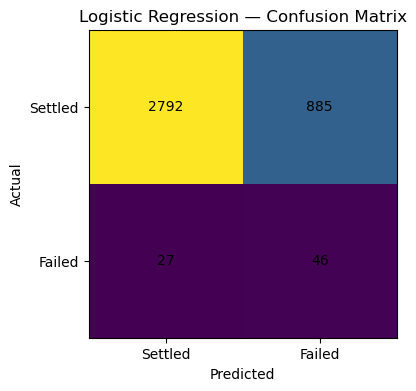

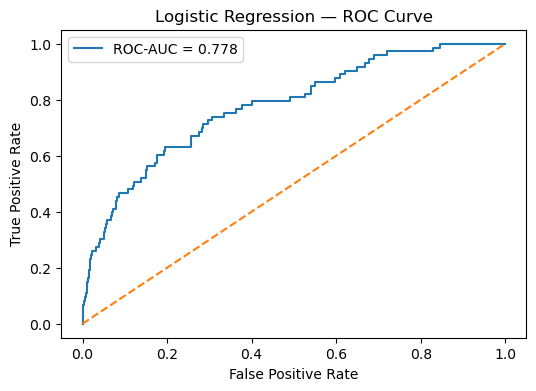

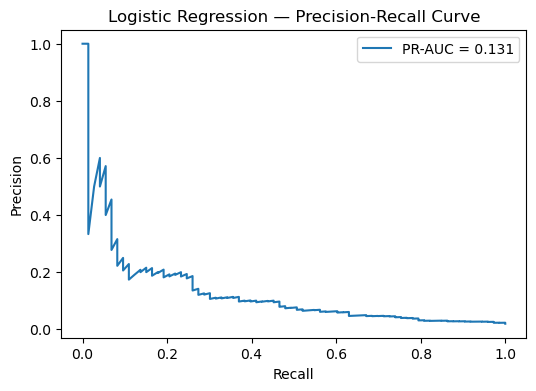

In [8]:
# ================================================================
# LOGISTIC REGRESSION — FULLY SELF-CONTAINED CLASSIFICATION SCENARIO
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression

# ---------- Load ----------
DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

# ---------- Leakage-safe engineered features ----------
df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["confirmation_delay_log"] = np.log1p(df["confirmation_delay_minutes"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"]
    + df["allocation_delay_minutes"]
    + df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["counterparty_risk_gap"] = df["prior_fail_rate_30d"] - df["prior_fail_rate_90d"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

TARGET = "settlement_failed"

FEATURES = [
    "asset_class", "buy_sell", "currency", "market", "settlement_location",
    "counterparty_id", "custodian", "trade_amount", "quantity",
    "settlement_days", "cross_border", "month_end", "quarter_end",
    "market_holiday_mismatch", "ssi_status", "confirmation_delay_minutes",
    "allocation_delay_minutes", "affirmation_delay_minutes", "matching_attempts",
    "trade_amendments", "hours_until_cutoff", "prior_fail_rate_30d",
    "prior_fail_rate_90d", "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "counterparty_avg_trade_amount", "trade_size_ratio",
    "log_trade_amount", "confirmation_delay_log", "processing_delay_total",
    "operational_touch_count", "counterparty_risk_gap", "cutoff_pressure"
]


# ---------- Temporal split: 70/15/15 ----------
n = len(df)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

train = df.iloc[:train_end]
validation = df.iloc[train_end:valid_end]
test = df.iloc[valid_end:]

X_train, y_train = train[FEATURES], train[TARGET].astype(int)
X_test, y_test = test[FEATURES], test[TARGET].astype(int)


X_fit = X_train
y_fit = y_train


numeric = X_train.select_dtypes(include=np.number).columns.tolist()
categorical = [c for c in FEATURES if c not in numeric]

prep = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), categorical),
])


# ---------- Model ----------
estimator = LogisticRegression(max_iter=1600, class_weight="balanced", random_state=42)

model = Pipeline([
    ("prep", prep),
    ("model", estimator),
])

model.fit(X_fit, y_fit)

# ---------- Predictions ----------
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.50).astype(int)

precision = precision_score(y_test, pred, zero_division=0)
recall = recall_score(y_test, pred, zero_division=0)
f1 = f1_score(y_test, pred, zero_division=0)
roc_auc = roc_auc_score(y_test, prob)
pr_auc = average_precision_score(y_test, prob)

print("Logistic Regression")
print("=" * len("Logistic Regression"))
print(classification_report(y_test, pred, digits=3, zero_division=0))

metrics = pd.DataFrame([{
    "Model": "Logistic Regression",
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
}])
display(metrics)

# ---------- Confusion matrix ----------
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title("Logistic Regression — Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_xticks([0, 1], labels=["Settled", "Failed"])
ax.set_yticks([0, 1], labels=["Settled", "Failed"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.show()

# ---------- ROC ----------
fpr, tpr, _ = roc_curve(y_test, prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
ax.plot([0,1], [0,1], linestyle="--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Logistic Regression — ROC Curve")
ax.legend()
plt.show()

# ---------- Precision-Recall ----------
p, r, _ = precision_recall_curve(y_test, prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(r, p, label=f"PR-AUC = {pr_auc:.3f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Logistic Regression — Precision-Recall Curve")
ax.legend()
plt.show()

# 8. K-Nearest Neighbors

Purpose: non-parametric similarity benchmark.  
Because KNN is distance-based, this version uses standardized numeric features.

K-Nearest Neighbors
              precision    recall  f1-score   support

           0      0.981     1.000     0.990      3677
           1      0.000     0.000     0.000        73

    accuracy                          0.981      3750
   macro avg      0.490     0.500     0.495      3750
weighted avg      0.961     0.981     0.971      3750



,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,K-Nearest Neighbors,0.0,0.0,0.0,0.544875,0.031086


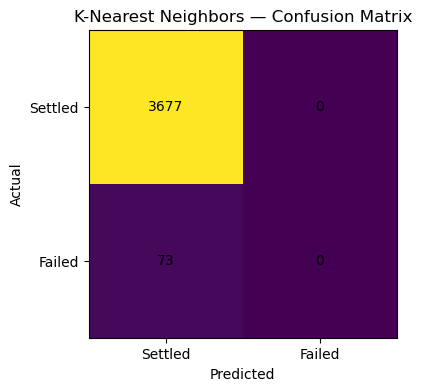

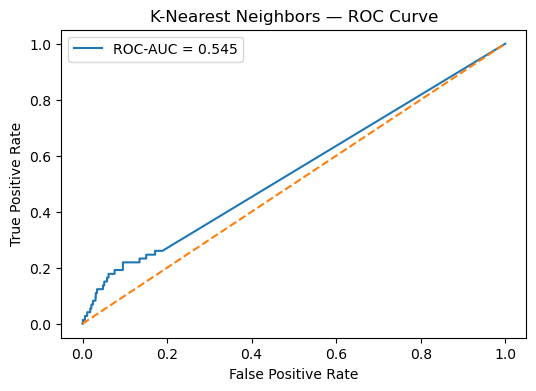

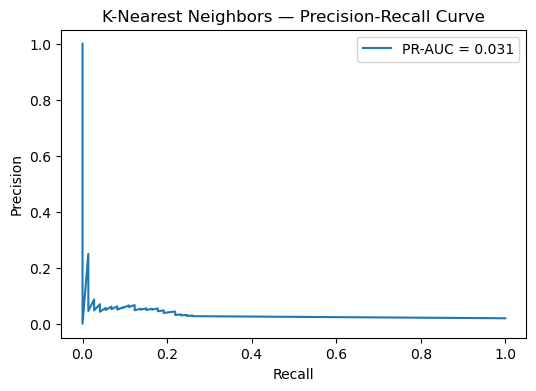

In [9]:
# ================================================================
# K-NEAREST NEIGHBORS — FULLY SELF-CONTAINED CLASSIFICATION SCENARIO
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve
)
from sklearn.neighbors import KNeighborsClassifier

# ---------- Load ----------
DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

# ---------- Leakage-safe engineered features ----------
df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["confirmation_delay_log"] = np.log1p(df["confirmation_delay_minutes"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"]
    + df["allocation_delay_minutes"]
    + df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["counterparty_risk_gap"] = df["prior_fail_rate_30d"] - df["prior_fail_rate_90d"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

TARGET = "settlement_failed"

FEATURES = [
    "trade_amount", "quantity", "settlement_days",
    "confirmation_delay_minutes", "allocation_delay_minutes",
    "affirmation_delay_minutes", "matching_attempts", "trade_amendments",
    "hours_until_cutoff", "prior_fail_rate_30d", "prior_fail_rate_90d",
    "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "trade_size_ratio", "processing_delay_total",
    "operational_touch_count", "cutoff_pressure"
]


# ---------- Temporal split: 70/15/15 ----------
n = len(df)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

train = df.iloc[:train_end]
validation = df.iloc[train_end:valid_end]
test = df.iloc[valid_end:]

X_train, y_train = train[FEATURES], train[TARGET].astype(int)
X_test, y_test = test[FEATURES], test[TARGET].astype(int)


X_fit = X_train
y_fit = y_train


prep = StandardScaler()


# ---------- Model ----------
estimator = KNeighborsClassifier(n_neighbors=15, weights="distance")

model = Pipeline([
    ("prep", prep),
    ("model", estimator),
])

model.fit(X_fit, y_fit)

# ---------- Predictions ----------
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.50).astype(int)

precision = precision_score(y_test, pred, zero_division=0)
recall = recall_score(y_test, pred, zero_division=0)
f1 = f1_score(y_test, pred, zero_division=0)
roc_auc = roc_auc_score(y_test, prob)
pr_auc = average_precision_score(y_test, prob)

print("K-Nearest Neighbors")
print("=" * len("K-Nearest Neighbors"))
print(classification_report(y_test, pred, digits=3, zero_division=0))

metrics = pd.DataFrame([{
    "Model": "K-Nearest Neighbors",
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
}])
display(metrics)

# ---------- Confusion matrix ----------
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title("K-Nearest Neighbors — Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_xticks([0, 1], labels=["Settled", "Failed"])
ax.set_yticks([0, 1], labels=["Settled", "Failed"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.show()

# ---------- ROC ----------
fpr, tpr, _ = roc_curve(y_test, prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
ax.plot([0,1], [0,1], linestyle="--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("K-Nearest Neighbors — ROC Curve")
ax.legend()
plt.show()

# ---------- Precision-Recall ----------
p, r, _ = precision_recall_curve(y_test, prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(r, p, label=f"PR-AUC = {pr_auc:.3f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("K-Nearest Neighbors — Precision-Recall Curve")
ax.legend()
plt.show()

# 9. Decision Tree

Purpose: highly interpretable nonlinear benchmark.  
Depth and leaf size are constrained to reduce overfitting.

Decision Tree
              precision    recall  f1-score   support

           0      0.988     0.652     0.786      3677
           1      0.033     0.603     0.063        73

    accuracy                          0.651      3750
   macro avg      0.511     0.628     0.424      3750
weighted avg      0.969     0.651     0.772      3750



,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Decision Tree,0.033283,0.60274,0.063082,0.638866,0.064811


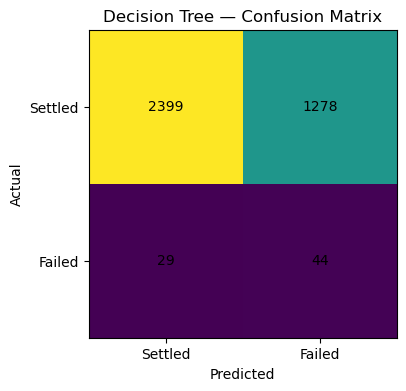

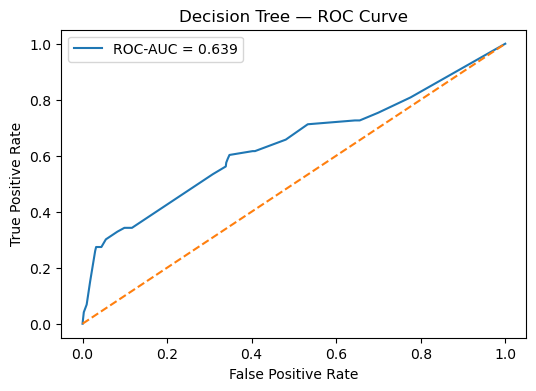

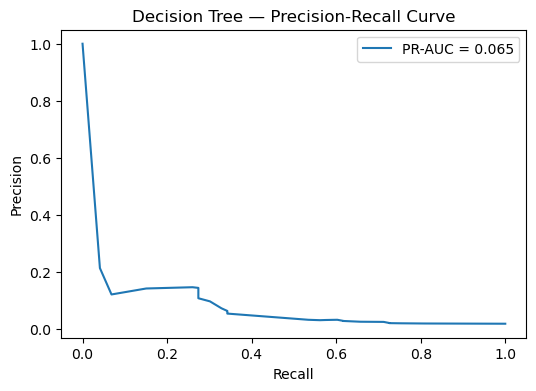

In [10]:
# ================================================================
# DECISION TREE — FULLY SELF-CONTAINED CLASSIFICATION SCENARIO
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve
)
from sklearn.tree import DecisionTreeClassifier

# ---------- Load ----------
DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

# ---------- Leakage-safe engineered features ----------
df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["confirmation_delay_log"] = np.log1p(df["confirmation_delay_minutes"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"]
    + df["allocation_delay_minutes"]
    + df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["counterparty_risk_gap"] = df["prior_fail_rate_30d"] - df["prior_fail_rate_90d"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

TARGET = "settlement_failed"

FEATURES = [
    "asset_class", "buy_sell", "currency", "market", "settlement_location",
    "counterparty_id", "custodian", "trade_amount", "quantity",
    "settlement_days", "cross_border", "month_end", "quarter_end",
    "market_holiday_mismatch", "ssi_status", "confirmation_delay_minutes",
    "allocation_delay_minutes", "affirmation_delay_minutes", "matching_attempts",
    "trade_amendments", "hours_until_cutoff", "prior_fail_rate_30d",
    "prior_fail_rate_90d", "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "counterparty_avg_trade_amount", "trade_size_ratio",
    "log_trade_amount", "confirmation_delay_log", "processing_delay_total",
    "operational_touch_count", "counterparty_risk_gap", "cutoff_pressure"
]


# ---------- Temporal split: 70/15/15 ----------
n = len(df)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

train = df.iloc[:train_end]
validation = df.iloc[train_end:valid_end]
test = df.iloc[valid_end:]

X_train, y_train = train[FEATURES], train[TARGET].astype(int)
X_test, y_test = test[FEATURES], test[TARGET].astype(int)


X_fit = X_train
y_fit = y_train


numeric = X_train.select_dtypes(include=np.number).columns.tolist()
categorical = [c for c in FEATURES if c not in numeric]

prep = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), categorical),
])


# ---------- Model ----------
estimator = DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, class_weight="balanced", random_state=42)

model = Pipeline([
    ("prep", prep),
    ("model", estimator),
])

model.fit(X_fit, y_fit)

# ---------- Predictions ----------
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.50).astype(int)

precision = precision_score(y_test, pred, zero_division=0)
recall = recall_score(y_test, pred, zero_division=0)
f1 = f1_score(y_test, pred, zero_division=0)
roc_auc = roc_auc_score(y_test, prob)
pr_auc = average_precision_score(y_test, prob)

print("Decision Tree")
print("=" * len("Decision Tree"))
print(classification_report(y_test, pred, digits=3, zero_division=0))

metrics = pd.DataFrame([{
    "Model": "Decision Tree",
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
}])
display(metrics)

# ---------- Confusion matrix ----------
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title("Decision Tree — Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_xticks([0, 1], labels=["Settled", "Failed"])
ax.set_yticks([0, 1], labels=["Settled", "Failed"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.show()

# ---------- ROC ----------
fpr, tpr, _ = roc_curve(y_test, prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
ax.plot([0,1], [0,1], linestyle="--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Decision Tree — ROC Curve")
ax.legend()
plt.show()

# ---------- Precision-Recall ----------
p, r, _ = precision_recall_curve(y_test, prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(r, p, label=f"PR-AUC = {pr_auc:.3f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Decision Tree — Precision-Recall Curve")
ax.legend()
plt.show()

# 10. Random Forest

Purpose: bagging/ensemble benchmark that can capture nonlinear interactions with less variance than one tree.

Random Forest
              precision    recall  f1-score   support

           0      0.981     0.999     0.989      3677
           1      0.000     0.000     0.000        73

    accuracy                          0.979      3750
   macro avg      0.490     0.499     0.495      3750
weighted avg      0.961     0.979     0.970      3750



,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Random Forest,0.0,0.0,0.0,0.716635,0.080164


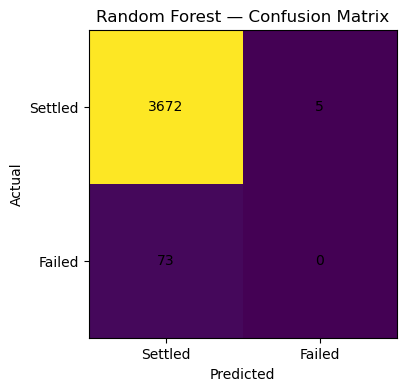

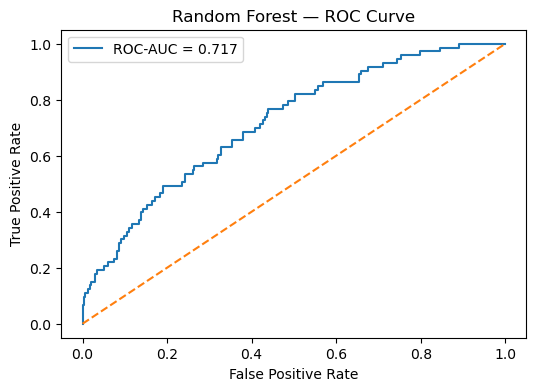

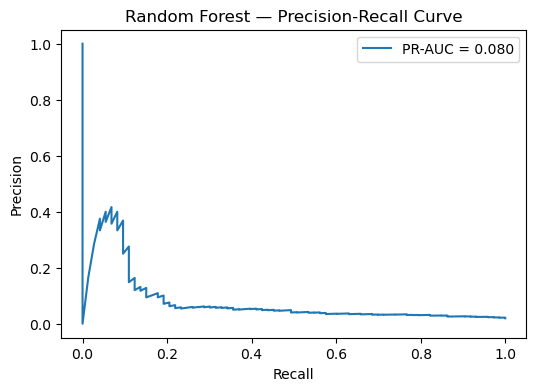

In [11]:
# ================================================================
# RANDOM FOREST — FULLY SELF-CONTAINED CLASSIFICATION SCENARIO
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve
)
from sklearn.ensemble import RandomForestClassifier

# ---------- Load ----------
DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

# ---------- Leakage-safe engineered features ----------
df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["confirmation_delay_log"] = np.log1p(df["confirmation_delay_minutes"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"]
    + df["allocation_delay_minutes"]
    + df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["counterparty_risk_gap"] = df["prior_fail_rate_30d"] - df["prior_fail_rate_90d"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

TARGET = "settlement_failed"

FEATURES = [
    "asset_class", "buy_sell", "currency", "market", "settlement_location",
    "counterparty_id", "custodian", "trade_amount", "quantity",
    "settlement_days", "cross_border", "month_end", "quarter_end",
    "market_holiday_mismatch", "ssi_status", "confirmation_delay_minutes",
    "allocation_delay_minutes", "affirmation_delay_minutes", "matching_attempts",
    "trade_amendments", "hours_until_cutoff", "prior_fail_rate_30d",
    "prior_fail_rate_90d", "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "counterparty_avg_trade_amount", "trade_size_ratio",
    "log_trade_amount", "confirmation_delay_log", "processing_delay_total",
    "operational_touch_count", "counterparty_risk_gap", "cutoff_pressure"
]


# ---------- Temporal split: 70/15/15 ----------
n = len(df)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

train = df.iloc[:train_end]
validation = df.iloc[train_end:valid_end]
test = df.iloc[valid_end:]

X_train, y_train = train[FEATURES], train[TARGET].astype(int)
X_test, y_test = test[FEATURES], test[TARGET].astype(int)


X_fit = X_train
y_fit = y_train


numeric = X_train.select_dtypes(include=np.number).columns.tolist()
categorical = [c for c in FEATURES if c not in numeric]

prep = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), categorical),
])


# ---------- Model ----------
estimator = RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5, class_weight="balanced_subsample", random_state=42, n_jobs=-1)

model = Pipeline([
    ("prep", prep),
    ("model", estimator),
])

model.fit(X_fit, y_fit)

# ---------- Predictions ----------
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.50).astype(int)

precision = precision_score(y_test, pred, zero_division=0)
recall = recall_score(y_test, pred, zero_division=0)
f1 = f1_score(y_test, pred, zero_division=0)
roc_auc = roc_auc_score(y_test, prob)
pr_auc = average_precision_score(y_test, prob)

print("Random Forest")
print("=" * len("Random Forest"))
print(classification_report(y_test, pred, digits=3, zero_division=0))

metrics = pd.DataFrame([{
    "Model": "Random Forest",
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
}])
display(metrics)

# ---------- Confusion matrix ----------
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title("Random Forest — Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_xticks([0, 1], labels=["Settled", "Failed"])
ax.set_yticks([0, 1], labels=["Settled", "Failed"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.show()

# ---------- ROC ----------
fpr, tpr, _ = roc_curve(y_test, prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
ax.plot([0,1], [0,1], linestyle="--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Random Forest — ROC Curve")
ax.legend()
plt.show()

# ---------- Precision-Recall ----------
p, r, _ = precision_recall_curve(y_test, prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(r, p, label=f"PR-AUC = {pr_auc:.3f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Random Forest — Precision-Recall Curve")
ax.legend()
plt.show()

# 11. Support Vector Machine

Purpose: nonlinear classical ML benchmark using an RBF kernel.  
The training sample is capped at 12,000 rows for practical runtime.

c:\AllTools\anaconda31\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Support Vector Machine
              precision    recall  f1-score   support

           0      0.981     1.000     0.990      3677
           1      0.000     0.000     0.000        73

    accuracy                          0.981      3750
   macro avg      0.490     0.500     0.495      3750
weighted avg      0.961     0.981     0.971      3750



,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Support Vector Machine,0.0,0.0,0.0,0.526475,0.025629


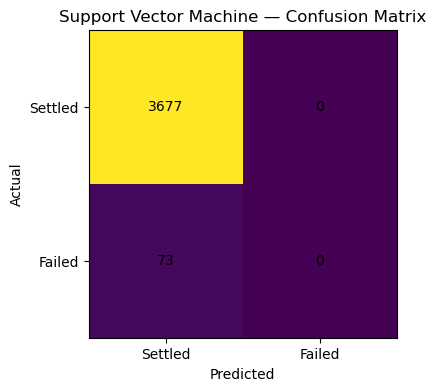

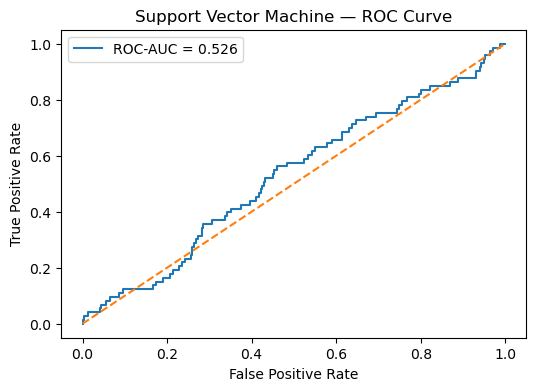

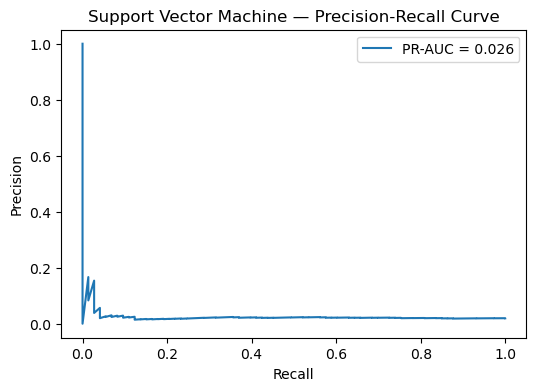

In [12]:
# ================================================================
# SUPPORT VECTOR MACHINE — FULLY SELF-CONTAINED CLASSIFICATION SCENARIO
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve
)
from sklearn.svm import SVC

# ---------- Load ----------
DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

# ---------- Leakage-safe engineered features ----------
df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["confirmation_delay_log"] = np.log1p(df["confirmation_delay_minutes"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"]
    + df["allocation_delay_minutes"]
    + df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["counterparty_risk_gap"] = df["prior_fail_rate_30d"] - df["prior_fail_rate_90d"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

TARGET = "settlement_failed"

FEATURES = [
    "trade_amount", "quantity", "settlement_days",
    "confirmation_delay_minutes", "allocation_delay_minutes",
    "affirmation_delay_minutes", "matching_attempts", "trade_amendments",
    "hours_until_cutoff", "prior_fail_rate_30d", "prior_fail_rate_90d",
    "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "trade_size_ratio", "processing_delay_total",
    "operational_touch_count", "cutoff_pressure"
]


# ---------- Temporal split: 70/15/15 ----------
n = len(df)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

train = df.iloc[:train_end]
validation = df.iloc[train_end:valid_end]
test = df.iloc[valid_end:]

X_train, y_train = train[FEATURES], train[TARGET].astype(int)
X_test, y_test = test[FEATURES], test[TARGET].astype(int)


# SVM can be computationally expensive. Use at most 12,000 training rows.
fit_df = train.sample(min(12000, len(train)), random_state=42)
X_fit = fit_df[FEATURES]
y_fit = fit_df[TARGET]


prep = StandardScaler()


# ---------- Model ----------
estimator = SVC(kernel="rbf", C=2.0, gamma="scale", class_weight="balanced", probability=True, random_state=42)

model = Pipeline([
    ("prep", prep),
    ("model", estimator),
])

model.fit(X_fit, y_fit)

# ---------- Predictions ----------
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.50).astype(int)

precision = precision_score(y_test, pred, zero_division=0)
recall = recall_score(y_test, pred, zero_division=0)
f1 = f1_score(y_test, pred, zero_division=0)
roc_auc = roc_auc_score(y_test, prob)
pr_auc = average_precision_score(y_test, prob)

print("Support Vector Machine")
print("=" * len("Support Vector Machine"))
print(classification_report(y_test, pred, digits=3, zero_division=0))

metrics = pd.DataFrame([{
    "Model": "Support Vector Machine",
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
}])
display(metrics)

# ---------- Confusion matrix ----------
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title("Support Vector Machine — Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_xticks([0, 1], labels=["Settled", "Failed"])
ax.set_yticks([0, 1], labels=["Settled", "Failed"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center")
plt.show()

# ---------- ROC ----------
fpr, tpr, _ = roc_curve(y_test, prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
ax.plot([0,1], [0,1], linestyle="--")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("Support Vector Machine — ROC Curve")
ax.legend()
plt.show()

# ---------- Precision-Recall ----------
p, r, _ = precision_recall_curve(y_test, prob)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(r, p, label=f"PR-AUC = {pr_auc:.3f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Support Vector Machine — Precision-Recall Curve")
ax.legend()
plt.show()

# 12. PCA and SVD

This cell independently performs dimensionality reduction on numeric predictive features and reports the number of components needed to explain 80%, 90%, and 95% of the variance.

PCA components for >=80% variance: 14
PCA components for >=90% variance: 16
PCA components for >=95% variance: 18


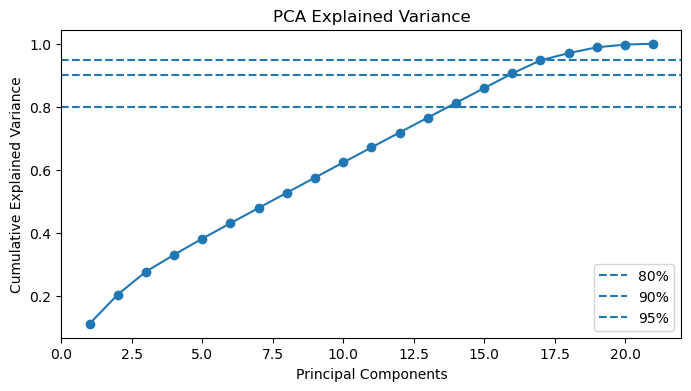

,Component,Singular_Value,Variance_Share,Cumulative_Variance
0,1,243.288703,0.112742,0.112742
1,2,220.464726,0.092580,0.205322
2,3,194.955945,0.072396,0.277718
3,4,167.991152,0.053754,0.331472
4,5,163.681115,0.051031,0.382504
5,6,159.914047,0.048710,0.431213
6,7,159.439590,0.048421,0.479634
7,8,159.254798,0.048309,0.527943
8,9,158.791700,0.048028,0.575971
9,10,158.214287,0.047680,0.623651


In [13]:
# ================================================================
# SCENARIO 12 — PCA + SVD
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH)

NUMERIC_FEATURES = [
    "trade_amount", "quantity", "settlement_days", "cross_border",
    "month_end", "quarter_end", "market_holiday_mismatch",
    "confirmation_delay_minutes", "allocation_delay_minutes",
    "affirmation_delay_minutes", "matching_attempts", "trade_amendments",
    "hours_until_cutoff", "prior_fail_rate_30d", "prior_fail_rate_90d",
    "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "counterparty_avg_trade_amount", "trade_size_ratio"
]

X = df[NUMERIC_FEATURES].fillna(df[NUMERIC_FEATURES].median())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA
pca = PCA()
pca.fit(X_scaled)
cum = np.cumsum(pca.explained_variance_ratio_)

def n_for(level):
    return int(np.argmax(cum >= level) + 1)

print("PCA components for >=80% variance:", n_for(0.80))
print("PCA components for >=90% variance:", n_for(0.90))
print("PCA components for >=95% variance:", n_for(0.95))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(cum)+1), cum, marker="o")
for level in [0.80, 0.90, 0.95]:
    ax.axhline(level, linestyle="--", label=f"{int(level*100)}%")
ax.set_xlabel("Principal Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.set_title("PCA Explained Variance")
ax.legend()
plt.show()

# SVD
U, sigma, VT = np.linalg.svd(X_scaled, full_matrices=False)
svd_share = sigma**2 / np.sum(sigma**2)
svd_cum = np.cumsum(svd_share)

svd_table = pd.DataFrame({
    "Component": np.arange(1, len(sigma)+1),
    "Singular_Value": sigma,
    "Variance_Share": svd_share,
    "Cumulative_Variance": svd_cum
})
display(svd_table.head(15))

# 13. K-Means Clustering

Question:

> Are there naturally occurring operational-risk profiles among trades?

The cell evaluates multiple values of `k`, plots inertia and silhouette score, then profiles a four-cluster solution.

,k,Inertia,Silhouette
0,2,199994.545318,0.459195
1,3,178629.995728,0.150773
2,4,163895.443862,0.115341
3,5,151676.558475,0.121855
4,6,141002.640950,0.124597
5,7,132472.605689,0.124106
6,8,125793.008496,0.122097


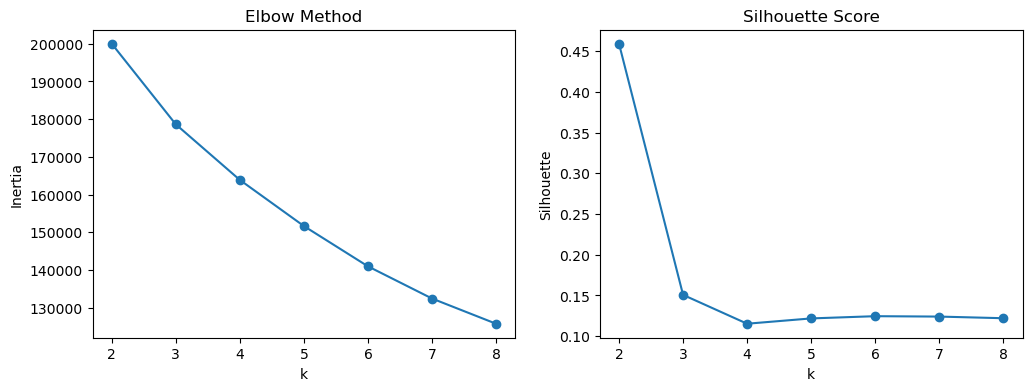

,log_trade_amount,processing_delay_total,operational_touch_count,hours_until_cutoff,prior_fail_rate_30d,security_liquidity_score,market_volatility_index,inventory_shortfall_indicator,trade_size_ratio,settlement_failed,Trade_Count
cluster,,,,,,,,,,,
0,15.9045,77.7999,1.7085,16.8186,0.0930,0.6730,20.1380,0.0015,16.0791,0.0373,2062
1,13.7902,77.8398,1.7818,16.7883,0.0951,0.7799,20.5746,0.0000,1.6586,0.0146,12812
2,13.8489,77.5771,1.6739,17.1715,0.0894,0.4890,19.5748,0.0000,1.7530,0.0187,9349
3,14.0424,76.7962,1.7027,16.9768,0.0914,0.6620,20.1762,1.0000,3.0090,0.0644,777


In [14]:
# ================================================================
# SCENARIO 13 — K-MEANS CLUSTERING
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH)

# Domain-oriented features for interpretable clusters.
df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"] +
    df["allocation_delay_minutes"] +
    df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]

FEATURES = [
    "log_trade_amount", "processing_delay_total",
    "operational_touch_count", "hours_until_cutoff",
    "prior_fail_rate_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "trade_size_ratio"
]

X = df[FEATURES].fillna(df[FEATURES].median())
X_scaled = StandardScaler().fit_transform(X)

rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_scaled), size=min(4000, len(X_scaled)), replace=False)

rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled[sample_idx], labels[sample_idx])
    rows.append({"k": k, "Inertia": model.inertia_, "Silhouette": sil})

selection = pd.DataFrame(rows)
display(selection)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(selection["k"], selection["Inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")

axes[1].plot(selection["k"], selection["Silhouette"], marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
plt.show()

# Business-interpretable demonstration with k=4.
kmeans = KMeans(n_clusters=4, random_state=42, n_init=20)
df["cluster"] = kmeans.fit_predict(X_scaled)

profile = df.groupby("cluster")[FEATURES + ["settlement_failed"]].mean()
profile["Trade_Count"] = df["cluster"].value_counts().sort_index()
display(profile.round(4))

# 14. Isolation Forest Anomaly Detection

Purpose: identify unusual trades even when the unusual pattern is not a known labeled failure mode.

In [15]:
# ================================================================
# SCENARIO 14 — ISOLATION FOREST
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH)

df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"] +
    df["allocation_delay_minutes"] +
    df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]

FEATURES = [
    "log_trade_amount", "processing_delay_total", "operational_touch_count",
    "hours_until_cutoff", "prior_fail_rate_30d",
    "security_liquidity_score", "market_volatility_index",
    "inventory_shortfall_indicator", "trade_size_ratio"
]

X = df[FEATURES].fillna(df[FEATURES].median())
X_scaled = StandardScaler().fit_transform(X)

model = IsolationForest(
    n_estimators=300,
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

labels = model.fit_predict(X_scaled)
df["is_anomaly"] = (labels == -1).astype(int)
df["anomaly_score"] = -model.score_samples(X_scaled)

summary = df.groupby("is_anomaly")["settlement_failed"].agg(["mean", "count"])
summary.index = ["Normal", "Anomaly"]
display(summary)

print("\nTop anomalous trades:")
display(
    df.nlargest(20, "anomaly_score")[
        ["trade_id", "settlement_failed", "anomaly_score"] + FEATURES
    ]
)

,mean,count
Normal,0.018408,24500
Anomaly,0.076000,500



Top anomalous trades:


,trade_id,settlement_failed,anomaly_score,log_trade_amount,processing_delay_total,operational_touch_count,hours_until_cutoff,prior_fail_rate_30d,security_liquidity_score,market_volatility_index,inventory_shortfall_indicator,trade_size_ratio
14923,TRD0005862,1,0.695696,16.958095,82.82,4,12.61,0.1892,0.7101,28.29,1,40.0000
5522,TRD0023156,0,0.684264,15.788158,194.75,3,18.62,0.1649,0.3715,21.44,1,30.1996
21008,TRD0005935,1,0.679738,15.939878,158.24,4,16.36,0.1229,0.6615,9.42,1,34.0663
255,TRD0013220,1,0.674373,15.497812,98.60,3,12.22,0.0479,0.2180,23.03,1,40.0000
18270,TRD0014825,0,0.669406,16.578514,87.91,2,20.57,0.0746,0.1336,18.63,1,40.0000
15021,TRD0006304,1,0.668495,16.934398,88.09,1,11.34,0.0110,0.4502,10.35,1,34.7152
9382,TRD0009833,0,0.667961,16.383549,93.46,1,2.06,0.0709,0.5778,15.36,1,40.0000
21849,TRD0012764,0,0.658430,16.959212,29.44,2,19.28,0.1139,0.6042,15.26,1,37.0879
4402,TRD0003052,0,0.657112,16.374493,114.59,4,16.93,0.2413,0.2127,27.02,0,26.8588
4581,TRD0001929,0,0.656392,17.048829,37.20,4,3.41,0.1183,0.6616,31.58,0,39.6772


# 15. XGBoost

This independently runnable cell includes the XGBoost dependency check, preprocessing, temporal split, class-imbalance weighting, model training, and rare-event metrics.

In [16]:
# ================================================================
# SCENARIO 15 — XGBOOST
# ================================================================

from pathlib import Path
import importlib.util
import subprocess, sys
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

if importlib.util.find_spec("xgboost") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "xgboost"])

from xgboost import XGBClassifier

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

# Features
df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"] +
    df["allocation_delay_minutes"] +
    df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["counterparty_risk_gap"] = df["prior_fail_rate_30d"] - df["prior_fail_rate_90d"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

FEATURES = [
    "asset_class", "buy_sell", "currency", "market", "settlement_location",
    "counterparty_id", "custodian", "trade_amount", "quantity",
    "settlement_days", "cross_border", "month_end", "quarter_end",
    "market_holiday_mismatch", "ssi_status", "confirmation_delay_minutes",
    "allocation_delay_minutes", "affirmation_delay_minutes",
    "matching_attempts", "trade_amendments", "hours_until_cutoff",
    "prior_fail_rate_30d", "prior_fail_rate_90d", "prior_trade_count_30d",
    "security_liquidity_score", "market_volatility_index",
    "inventory_shortfall_indicator", "counterparty_avg_trade_amount",
    "trade_size_ratio", "log_trade_amount", "processing_delay_total",
    "operational_touch_count", "counterparty_risk_gap", "cutoff_pressure"
]
TARGET = "settlement_failed"

n = len(df)
train_end = int(n * 0.70)
test_start = int(n * 0.85)

train = df.iloc[:train_end]
test = df.iloc[test_start:]

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

numeric = X_train.select_dtypes(include=np.number).columns.tolist()
categorical = [c for c in FEATURES if c not in numeric]

prep = ColumnTransformer([
    ("num", "passthrough", numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), categorical)
])

neg = int((y_train == 0).sum())
pos = int((y_train == 1).sum())
scale_pos_weight = neg / max(pos, 1)

model = Pipeline([
    ("prep", prep),
    ("model", XGBClassifier(
        n_estimators=350,
        max_depth=5,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        min_child_weight=4,
        reg_lambda=2.0,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.50).astype(int)

print(classification_report(y_test, pred, digits=3, zero_division=0))
display(pd.DataFrame([{
    "Model": "XGBoost",
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1": f1_score(y_test, pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, prob),
    "PR_AUC": average_precision_score(y_test, prob),
}]))

              precision    recall  f1-score   support

           0      0.985     0.964     0.974      3677
           1      0.119     0.247     0.161        73

    accuracy                          0.950      3750
   macro avg      0.552     0.605     0.567      3750
weighted avg      0.968     0.950     0.958      3750



,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,XGBoost,0.119205,0.246575,0.160714,0.69499,0.091753


# 16. CatBoost

CatBoost is particularly relevant for trade datasets containing many categorical variables. This cell uses CatBoost's native categorical-feature handling.

In [17]:
# ================================================================
# SCENARIO 16 — CATBOOST
# ================================================================

from pathlib import Path
import importlib.util
import subprocess, sys
import pandas as pd
import numpy as np

from sklearn.metrics import (
    classification_report, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

if importlib.util.find_spec("catboost") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "catboost"])

from catboost import CatBoostClassifier

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"] +
    df["allocation_delay_minutes"] +
    df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["counterparty_risk_gap"] = df["prior_fail_rate_30d"] - df["prior_fail_rate_90d"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

FEATURES = [
    "asset_class", "buy_sell", "currency", "market", "settlement_location",
    "counterparty_id", "custodian", "trade_amount", "quantity",
    "settlement_days", "cross_border", "month_end", "quarter_end",
    "market_holiday_mismatch", "ssi_status", "confirmation_delay_minutes",
    "allocation_delay_minutes", "affirmation_delay_minutes",
    "matching_attempts", "trade_amendments", "hours_until_cutoff",
    "prior_fail_rate_30d", "prior_fail_rate_90d", "prior_trade_count_30d",
    "security_liquidity_score", "market_volatility_index",
    "inventory_shortfall_indicator", "counterparty_avg_trade_amount",
    "trade_size_ratio", "log_trade_amount", "processing_delay_total",
    "operational_touch_count", "counterparty_risk_gap", "cutoff_pressure"
]
TARGET = "settlement_failed"

n = len(df)
train_end = int(n * 0.70)
test_start = int(n * 0.85)

train = df.iloc[:train_end].copy()
test = df.iloc[test_start:].copy()

X_train = train[FEATURES].copy()
y_train = train[TARGET].astype(int)
X_test = test[FEATURES].copy()
y_test = test[TARGET].astype(int)

categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()
cat_indices = [X_train.columns.get_loc(c) for c in categorical_cols]

for c in categorical_cols:
    X_train[c] = X_train[c].fillna("UNKNOWN").astype(str)
    X_test[c] = X_test[c].fillna("UNKNOWN").astype(str)

model = CatBoostClassifier(
    iterations=450,
    depth=6,
    learning_rate=0.04,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=False
)

model.fit(X_train, y_train, cat_features=cat_indices)

prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.50).astype(int)

print(classification_report(y_test, pred, digits=3, zero_division=0))
display(pd.DataFrame([{
    "Model": "CatBoost",
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred, zero_division=0),
    "F1": f1_score(y_test, pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, prob),
    "PR_AUC": average_precision_score(y_test, prob),
}]))

              precision    recall  f1-score   support

           0      0.985     0.969     0.977      3677
           1      0.130     0.233     0.167        73

    accuracy                          0.955      3750
   macro avg      0.557     0.601     0.572      3750
weighted avg      0.968     0.955     0.961      3750



,Model,Precision,Recall,F1,ROC_AUC,PR_AUC
0,CatBoost,0.129771,0.232877,0.166667,0.706498,0.116896


# 17. Threshold and Business-Cost Optimization

This scenario intentionally uses a fully self-contained Logistic Regression pipeline so the threshold experiment does not depend on any earlier trained model.

Illustrative assumptions:

- False negative = `$5,000`
- False positive = `$50`

These are academic assumptions, not real institutional costs.

,Threshold,Precision,Recall,F1,Alerts,False_Negatives,False_Positives,Illustrative_Cost
0,0.05,0.020550,1.000000,0.040272,3747,0,3670,183500
1,0.10,0.021084,1.000000,0.041298,3652,0,3575,178750
2,0.15,0.022163,0.974026,0.043340,3384,2,3309,175450
3,0.20,0.024967,0.974026,0.048685,3004,2,2929,156450
4,0.25,0.026224,0.883117,0.050936,2593,9,2525,171250
5,0.30,0.029104,0.831169,0.056239,2199,13,2135,171750
6,0.35,0.032584,0.753247,0.062466,1780,19,1722,181100
7,0.40,0.040166,0.753247,0.076266,1444,19,1386,164300
8,0.45,0.043947,0.688312,0.082619,1206,24,1153,177650
9,0.50,0.048205,0.610390,0.089354,975,30,928,196400



Selected validation threshold: 0.2
Validation illustrative expected cost: $156,450

FINAL TEST METRICS AT SELECTED THRESHOLD
Precision: 0.024
Recall: 0.973
F1: 0.047


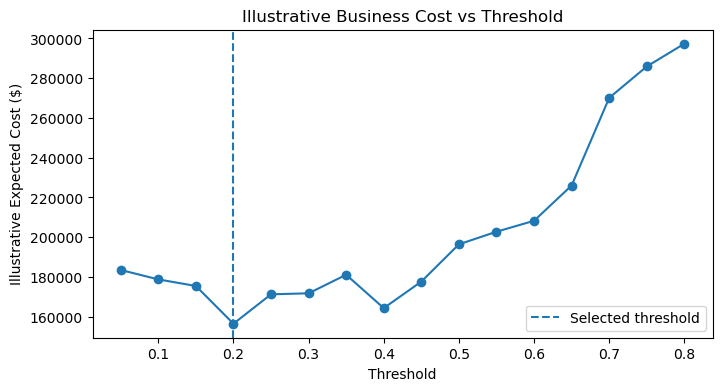

In [18]:
# ================================================================
# SCENARIO 17 — THRESHOLD + BUSINESS COST OPTIMIZATION
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"] +
    df["allocation_delay_minutes"] +
    df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["counterparty_risk_gap"] = df["prior_fail_rate_30d"] - df["prior_fail_rate_90d"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

FEATURES = [
    "asset_class", "currency", "market", "settlement_location",
    "ssi_status", "trade_amount", "quantity", "settlement_days",
    "cross_border", "month_end", "quarter_end",
    "confirmation_delay_minutes", "allocation_delay_minutes",
    "affirmation_delay_minutes", "matching_attempts", "trade_amendments",
    "hours_until_cutoff", "prior_fail_rate_30d", "prior_fail_rate_90d",
    "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "trade_size_ratio", "log_trade_amount", "processing_delay_total",
    "operational_touch_count", "counterparty_risk_gap", "cutoff_pressure"
]
TARGET = "settlement_failed"

n = len(df)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

train = df.iloc[:train_end]
validation = df.iloc[train_end:valid_end]
test = df.iloc[valid_end:]

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = validation[FEATURES], validation[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

numeric = X_train.select_dtypes(include=np.number).columns.tolist()
categorical = [c for c in FEATURES if c not in numeric]

prep = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), categorical),
])

model = Pipeline([
    ("prep", prep),
    ("model", LogisticRegression(
        max_iter=1600,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

# Select threshold on VALIDATION data only.
valid_prob = model.predict_proba(X_valid)[:, 1]

FALSE_NEGATIVE_COST = 5000
FALSE_POSITIVE_COST = 50

rows = []
for threshold in np.arange(0.05, 0.81, 0.05):
    pred = (valid_prob >= threshold).astype(int)
    fn = int(((y_valid == 1) & (pred == 0)).sum())
    fp = int(((y_valid == 0) & (pred == 1)).sum())

    rows.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1": f1_score(y_valid, pred, zero_division=0),
        "Alerts": int(pred.sum()),
        "False_Negatives": fn,
        "False_Positives": fp,
        "Illustrative_Cost": fn * FALSE_NEGATIVE_COST + fp * FALSE_POSITIVE_COST
    })

threshold_table = pd.DataFrame(rows)
display(threshold_table)

best = threshold_table.loc[threshold_table["Illustrative_Cost"].idxmin()]
best_threshold = float(best["Threshold"])

print("\nSelected validation threshold:", best_threshold)
print("Validation illustrative expected cost:", f'${best["Illustrative_Cost"]:,.0f}')

# Evaluate selected threshold once on TEST data.
test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

print("\nFINAL TEST METRICS AT SELECTED THRESHOLD")
print("Precision:", f"{precision_score(y_test, test_pred, zero_division=0):.3f}")
print("Recall:", f"{recall_score(y_test, test_pred, zero_division=0):.3f}")
print("F1:", f"{f1_score(y_test, test_pred, zero_division=0):.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(threshold_table["Threshold"], threshold_table["Illustrative_Cost"], marker="o")
ax.axvline(best_threshold, linestyle="--", label="Selected threshold")
ax.set_title("Illustrative Business Cost vs Threshold")
ax.set_xlabel("Threshold")
ax.set_ylabel("Illustrative Expected Cost ($)")
ax.legend()
plt.show()

# 18. SHAP Explainability

This self-contained scenario trains a Random Forest and computes global SHAP importance.  
Random Forest is used because tree explainers are efficient and stable for this demonstration.

c:\AllTools\anaconda31\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROC-AUC: 0.663
PR-AUC: 0.034


,Feature,Mean_Absolute_SHAP
13,prior_fail_rate_30d,0.042401
24,counterparty_risk_gap,0.040180
14,prior_fail_rate_90d,0.037983
20,trade_size_ratio,0.029348
12,hours_until_cutoff,0.023010
16,security_liquidity_score,0.022973
0,trade_amount,0.022845
21,log_trade_amount,0.022542
8,allocation_delay_minutes,0.022190
7,confirmation_delay_minutes,0.021710


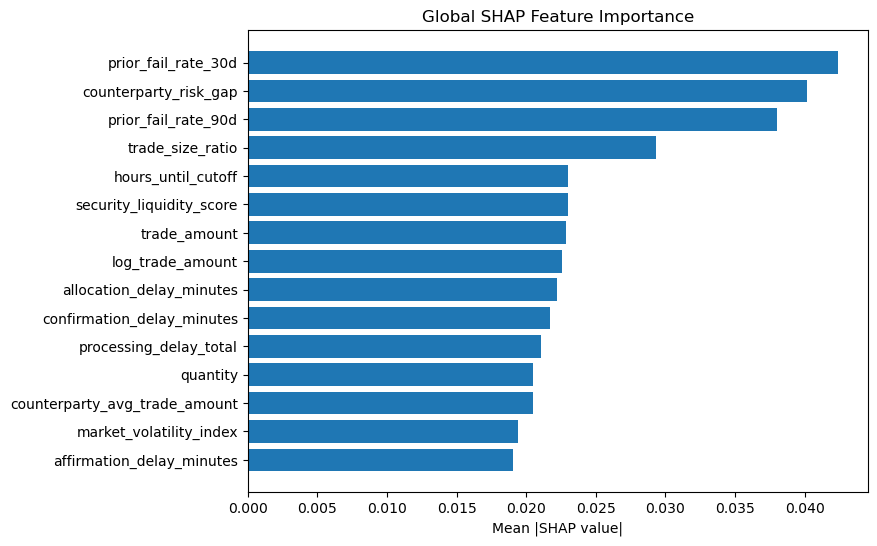

In [19]:
# ================================================================
# SCENARIO 18 — SHAP EXPLAINABILITY
# ================================================================

from pathlib import Path
import importlib.util
import subprocess, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

if importlib.util.find_spec("shap") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "shap"])

import shap

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

# Use numeric features so SHAP explanations map directly to original business variables.
df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"] +
    df["allocation_delay_minutes"] +
    df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["counterparty_risk_gap"] = df["prior_fail_rate_30d"] - df["prior_fail_rate_90d"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

FEATURES = [
    "trade_amount", "quantity", "settlement_days", "cross_border",
    "month_end", "quarter_end", "market_holiday_mismatch",
    "confirmation_delay_minutes", "allocation_delay_minutes",
    "affirmation_delay_minutes", "matching_attempts", "trade_amendments",
    "hours_until_cutoff", "prior_fail_rate_30d", "prior_fail_rate_90d",
    "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "counterparty_avg_trade_amount", "trade_size_ratio",
    "log_trade_amount", "processing_delay_total",
    "operational_touch_count", "counterparty_risk_gap", "cutoff_pressure"
]
TARGET = "settlement_failed"

n = len(df)
train_end = int(n * 0.70)
test_start = int(n * 0.85)
train = df.iloc[:train_end]
test = df.iloc[test_start:]

X_train = train[FEATURES].fillna(train[FEATURES].median())
y_train = train[TARGET].astype(int)
X_test = test[FEATURES].fillna(train[FEATURES].median())
y_test = test[TARGET].astype(int)

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=5,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

prob = model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", f"{roc_auc_score(y_test, prob):.3f}")
print("PR-AUC:", f"{average_precision_score(y_test, prob):.3f}")

sample = X_test.head(min(500, len(X_test)))
explainer = shap.TreeExplainer(model)
values = explainer.shap_values(sample)

if isinstance(values, list):
    shap_array = values[-1]
else:
    shap_array = np.asarray(values)
    if shap_array.ndim == 3:
        shap_array = shap_array[:, :, -1]

importance = pd.DataFrame({
    "Feature": FEATURES,
    "Mean_Absolute_SHAP": np.abs(shap_array).mean(axis=0)
}).sort_values("Mean_Absolute_SHAP", ascending=False)

display(importance.head(20))

top = importance.head(15).sort_values("Mean_Absolute_SHAP")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["Feature"], top["Mean_Absolute_SHAP"])
ax.set_title("Global SHAP Feature Importance")
ax.set_xlabel("Mean |SHAP value|")
plt.show()

# 19. NLP — Failure Reason Classification

This is explicitly a **post-event** use case.  
`failure_reason_description` is never used in the pre-settlement model.

The cell uses TF-IDF + Logistic Regression to classify failure categories.

In [20]:
# ================================================================
# SCENARIO 19 — NLP FAILURE-REASON CLASSIFICATION
# ================================================================

from pathlib import Path
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date")

failed = df.loc[
    df["settlement_failed"] == 1,
    ["failure_reason_description", "failure_reason", "trade_date"]
].dropna().reset_index(drop=True)

cut = int(len(failed) * 0.80)
train = failed.iloc[:cut]
test = failed.iloc[cut:]

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        max_features=5000
    )),
    ("model", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(train["failure_reason_description"], train["failure_reason"])
pred = model.predict(test["failure_reason_description"])

print(classification_report(
    test["failure_reason"],
    pred,
    digits=3,
    zero_division=0
))

examples = pd.DataFrame({
    "Description": test["failure_reason_description"].head(15),
    "Actual": test["failure_reason"].head(15),
    "Predicted": pred[:15]
})
display(examples)

                                     precision    recall  f1-score   support

     Counterparty Operational Issue      1.000     1.000     1.000        39
               Funding / Cash Issue      1.000     1.000     1.000         5
Insufficient Securities / Inventory      1.000     1.000     1.000         6
    Late Confirmation / Affirmation      1.000     1.000     1.000         8
 Market Holiday / Calendar Mismatch      1.000     1.000     1.000         4
        Other Operational Exception      1.000     1.000     1.000         5
       SSI / Settlement Instruction      1.000     1.000     1.000        21
               Trade Matching Break      1.000     1.000     1.000        10

                           accuracy                          1.000        98
                          macro avg      1.000     1.000     1.000        98
                       weighted avg      1.000     1.000     1.000        98



,Description,Actual,Predicted
391,Settlement failed after delayed confirmation o...,Late Confirmation / Affirmation,Late Confirmation / Affirmation
392,Settlement failed due to insufficient securiti...,Insufficient Securities / Inventory,Insufficient Securities / Inventory
393,Settlement failed due to a counterparty operat...,Counterparty Operational Issue,Counterparty Operational Issue
394,Settlement failed because required funding or ...,Funding / Cash Issue,Funding / Cash Issue
395,Settlement failed because settlement instructi...,SSI / Settlement Instruction,SSI / Settlement Instruction
396,Settlement failed because settlement instructi...,SSI / Settlement Instruction,SSI / Settlement Instruction
397,Settlement failed due to a counterparty operat...,Counterparty Operational Issue,Counterparty Operational Issue
398,Settlement failed due to a counterparty operat...,Counterparty Operational Issue,Counterparty Operational Issue
399,Settlement failed due to a counterparty operat...,Counterparty Operational Issue,Counterparty Operational Issue
400,Settlement failed after delayed confirmation o...,Late Confirmation / Affirmation,Late Confirmation / Affirmation


# 20. Grounded GenAI-Ready Risk Narrative

This cell is intentionally independent and requires no external LLM API.

It demonstrates the **safe output contract** that a later GenAI model could consume:

- model probability,
- grounded risk drivers,
- recommended action,
- explicit uncertainty statement.

In [21]:
# ================================================================
# SCENARIO 20 — GROUNDED GENAI-READY EXPLANATION TEMPLATE
# ================================================================

def grounded_risk_narrative(
    trade_id,
    probability,
    top_drivers,
    recommended_actions=None
):
    """
    Produce a grounded operational narrative.

    IMPORTANT:
    - probability must come from an ML model;
    - drivers must come from explainability or validated rules;
    - this function does not invent a failure reason;
    - output is decision support, not an autonomous trade decision.
    """
    if probability >= 0.80:
        risk_band = "CRITICAL"
    elif probability >= 0.60:
        risk_band = "HIGH"
    elif probability >= 0.30:
        risk_band = "MEDIUM"
    else:
        risk_band = "LOW"

    drivers = "; ".join(top_drivers[:4]) if top_drivers else "No dominant risk driver identified"
    actions = (
        "; ".join(recommended_actions)
        if recommended_actions
        else "Review according to standard operations procedures"
    )

    return (
        f"Trade {trade_id} has a modeled settlement-failure probability "
        f"of {probability:.1%} ({risk_band} risk). "
        f"Primary grounded risk drivers: {drivers}. "
        f"Suggested operational follow-up: {actions}. "
        "This is a model-based decision-support estimate, not a guaranteed outcome."
    )

example = grounded_risk_narrative(
    "TRD-EXAMPLE",
    0.87,
    [
        "SSI is missing or recently changed",
        "recent counterparty failure rate is elevated",
        "confirmation delay is high",
        "trade size is above the counterparty norm",
    ],
    [
        "validate settlement instructions",
        "contact the counterparty before cutoff",
    ]
)

print(example)

Trade TRD-EXAMPLE has a modeled settlement-failure probability of 87.0% (CRITICAL risk). Primary grounded risk drivers: SSI is missing or recently changed; recent counterparty failure rate is elevated; confirmation delay is high; trade size is above the counterparty norm. Suggested operational follow-up: validate settlement instructions; contact the counterparty before cutoff. This is a model-based decision-support estimate, not a guaranteed outcome.


# 21. End-to-End Operations Risk Queue

This self-contained cell trains a leakage-safe Logistic Regression model, scores the final temporal test period, and creates a ranked operations queue.

In [22]:
# ================================================================
# SCENARIO 21 — END-TO-END HIGH-RISK OPERATIONS QUEUE
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["trade_date", "settlement_date"]
).sort_values("trade_date").reset_index(drop=True)

df["log_trade_amount"] = np.log1p(df["trade_amount"])
df["processing_delay_total"] = (
    df["confirmation_delay_minutes"] +
    df["allocation_delay_minutes"] +
    df["affirmation_delay_minutes"]
)
df["operational_touch_count"] = df["matching_attempts"] + df["trade_amendments"]
df["counterparty_risk_gap"] = df["prior_fail_rate_30d"] - df["prior_fail_rate_90d"]
df["cutoff_pressure"] = (df["hours_until_cutoff"] < 8).astype(int)

FEATURES = [
    "asset_class", "currency", "market", "settlement_location",
    "counterparty_id", "custodian", "ssi_status",
    "trade_amount", "quantity", "settlement_days", "cross_border",
    "confirmation_delay_minutes", "allocation_delay_minutes",
    "affirmation_delay_minutes", "matching_attempts", "trade_amendments",
    "hours_until_cutoff", "prior_fail_rate_30d", "prior_fail_rate_90d",
    "prior_trade_count_30d", "security_liquidity_score",
    "market_volatility_index", "inventory_shortfall_indicator",
    "trade_size_ratio", "log_trade_amount", "processing_delay_total",
    "operational_touch_count", "counterparty_risk_gap", "cutoff_pressure"
]
TARGET = "settlement_failed"

n = len(df)
train_end = int(n * 0.70)
test_start = int(n * 0.85)

train = df.iloc[:train_end]
test = df.iloc[test_start:].copy()

X_train, y_train = train[FEATURES], train[TARGET]
X_test = test[FEATURES]

numeric = X_train.select_dtypes(include=np.number).columns.tolist()
categorical = [c for c in FEATURES if c not in numeric]

prep = ColumnTransformer([
    ("num", StandardScaler(), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5), categorical)
])

model = Pipeline([
    ("prep", prep),
    ("model", LogisticRegression(
        max_iter=1600,
        class_weight="balanced",
        random_state=42
    ))
])
model.fit(X_train, y_train)

test["predicted_failure_probability"] = model.predict_proba(X_test)[:, 1]

# Illustrative operational routing threshold.
ROUTING_THRESHOLD = 0.30

def risk_band(p):
    if p >= 0.80:
        return "CRITICAL"
    if p >= 0.60:
        return "HIGH"
    if p >= 0.30:
        return "MEDIUM"
    return "LOW"

test["risk_band"] = test["predicted_failure_probability"].apply(risk_band)
test["route_for_review"] = (
    test["predicted_failure_probability"] >= ROUTING_THRESHOLD
).astype(int)

queue = (
    test.loc[test["route_for_review"] == 1, [
        "trade_id", "trade_date", "settlement_date",
        "asset_class", "counterparty_id", "trade_amount",
        "ssi_status", "confirmation_delay_minutes",
        "prior_fail_rate_30d", "inventory_shortfall_indicator",
        "predicted_failure_probability", "risk_band",
        "settlement_failed"
    ]]
    .sort_values("predicted_failure_probability", ascending=False)
)

print("Routing threshold:", ROUTING_THRESHOLD)
print("Trades routed for review:", len(queue))
display(queue.head(30))

Routing threshold: 0.3
Trades routed for review: 1918


,trade_id,trade_date,settlement_date,asset_class,counterparty_id,trade_amount,ssi_status,confirmation_delay_minutes,prior_fail_rate_30d,inventory_shortfall_indicator,predicted_failure_probability,risk_band,settlement_failed
21469,TRD0014790,2025-06-30,2025-07-01,Equity,CP079,6071119.29,MISSING,35.36,0.2127,0,0.990258,CRITICAL,1
22820,TRD0015122,2025-08-29,2025-08-30,Corporate Bond,CP063,3764069.57,CHANGED,7.74,0.2942,0,0.985536,CRITICAL,0
23106,TRD0000452,2025-09-10,2025-09-13,Equity,CP039,1575371.64,MISSING,43.97,0.2080,0,0.985031,CRITICAL,1
23955,TRD0015401,2025-10-17,2025-10-19,Government Bond,CP060,448870.01,MISSING,45.48,0.1655,1,0.984319,CRITICAL,1
21515,TRD0000232,2025-07-01,2025-07-03,Equity,CP059,1703158.81,MISSING,40.57,0.0833,1,0.981724,CRITICAL,0
21387,TRD0001856,2025-06-25,2025-06-26,Government Bond,CP028,8257775.35,MISSING,18.71,0.1671,0,0.981618,CRITICAL,1
21748,TRD0018773,2025-07-11,2025-07-13,ETF,CP024,9116088.61,MISSING,40.19,0.2044,0,0.972124,CRITICAL,0
24235,TRD0020841,2025-10-29,2025-10-30,ETF,CP021,6578132.19,MISSING,83.52,0.0194,0,0.971733,CRITICAL,0
23803,TRD0015548,2025-10-09,2025-10-10,Equity,CP063,1149287.43,MISSING,75.38,0.2981,0,0.970119,CRITICAL,0
24000,TRD0015072,2025-10-20,2025-10-22,Equity,CP014,4202146.24,VALID,5.03,0.0909,1,0.968024,CRITICAL,0


# 22. Data Drift / PSI Monitoring

This cell independently compares the training period with the final test period using Population Stability Index (PSI).

In [23]:
# ================================================================
# SCENARIO 22 — PSI DATA-DRIFT MONITORING
# ================================================================

from pathlib import Path
import pandas as pd
import numpy as np

DATA_CANDIDATES = [
    Path("trade_settlement_synthetic.csv"),
    Path("data/trade_settlement_synthetic.csv"),
    Path("../data/trade_settlement_synthetic.csv"),
    Path("/mnt/data/trade_failure_capstone_starter/data/trade_settlement_synthetic.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found.")

df = pd.read_csv(DATA_PATH, parse_dates=["trade_date"]).sort_values("trade_date").reset_index(drop=True)

n = len(df)
train_end = int(n * 0.70)
test_start = int(n * 0.85)

train = df.iloc[:train_end]
test = df.iloc[test_start:]

def psi(expected, actual, bins=10):
    expected = pd.Series(expected).dropna()
    actual = pd.Series(actual).dropna()

    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return np.nan

    e = pd.cut(expected, bins=edges, include_lowest=True).value_counts(sort=False)
    a = pd.cut(actual, bins=edges, include_lowest=True).value_counts(sort=False)

    e_pct = (e / e.sum()).replace(0, 1e-6)
    a_pct = (a / max(a.sum(), 1)).replace(0, 1e-6)
    a_pct = a_pct.reindex(e_pct.index, fill_value=1e-6)

    return float(((a_pct - e_pct) * np.log(a_pct / e_pct)).sum())

FEATURES = [
    "trade_amount",
    "confirmation_delay_minutes",
    "prior_fail_rate_30d",
    "security_liquidity_score",
    "market_volatility_index",
    "trade_size_ratio",
]

rows = []
for feature in FEATURES:
    value = psi(train[feature], test[feature])
    rows.append({
        "Feature": feature,
        "PSI": value,
        "Illustrative_Interpretation": (
            "Low shift" if pd.notna(value) and value < 0.10 else
            "Moderate shift" if pd.notna(value) and value < 0.25 else
            "High shift"
        )
    })

drift = pd.DataFrame(rows).sort_values("PSI", ascending=False)
display(drift)

,Feature,PSI,Illustrative_Interpretation
5,trade_size_ratio,0.005025,Low shift
0,trade_amount,0.004252,Low shift
4,market_volatility_index,0.003066,Low shift
2,prior_fail_rate_30d,0.002350,Low shift
1,confirmation_delay_minutes,0.002080,Low shift
3,security_liquidity_score,0.001521,Low shift


# 23. Final Submission Interpretation Template

After running all desired cells, your written conclusions should report the **actual results** rather than generic statements.

### Required findings

- Observed synthetic failure rate
- Strongest EDA relationships
- Statistical-test conclusions
- Regression performance
- Logistic Regression metrics
- KNN metrics
- Decision Tree metrics
- Random Forest metrics
- SVM metrics
- XGBoost metrics
- CatBoost metrics
- PCA component counts
- K-Means cluster profiles
- Isolation Forest anomaly characteristics
- Threshold/cost trade-off
- SHAP top features
- NLP results
- Operational high-risk queue implications
- Drift-monitoring findings

### Business recommendations

1. Risk-based pre-settlement prioritization
2. Earlier intervention on high-risk trades
3. Explainable risk drivers for operations users
4. Threshold selection aligned with operational capacity
5. Human-in-the-loop decision making
6. Production monitoring and periodic revalidation

# 24. Responsible AI and Limitations

### Responsible AI

- Human oversight
- Explainability
- Auditability
- Point-in-time data lineage
- Access control
- Independent model validation
- Bias/fairness review
- Change management
- Grounded GenAI usage

### Limitations

- Synthetic data
- Designed signal relationships
- Simplified external-market context
- Illustrative business costs
- Predictive association is not causality
- Production calibration would require separate validation
- Real-world model/data drift
- NLP failure descriptions are post-event only

# 25. Final Checklist

- [✅] Run dependency cell once in the target environment
- [✅] Verify the CSV path
- [✅] Run each scenario independently to confirm portability
- [✅] Run the notebook top-to-bottom once before submission
- [✅] Retain outputs, tables, and charts
- [✅] Replace generic interpretation text with actual measured findings
- [✅] Document the selected final model and why
- [✅] Verify post-outcome fields are excluded from prediction
- [✅] Label synthetic data clearly
- [✅] Label business-cost assumptions as illustrative
- [✅] Add formal references required by the course
- [✅] Confirm GitHub renders the notebook correctly
- [✅] Do not include confidential employer data, systems, or code